<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-11/lab-067-atom-light-qubit.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 067. An atom in laser light as a qubit

A qubit is any quantum system with two orthogonal states. One of the most precise ways to build it is to take two energy levels of an atom or an ion and drive them with laser light. An atom has infinitely many bound states, and its electron could in principle be pushed into any of them. We follow on the computer how an atom in a laser field turns into a two-level system, and how the laser pulse turns into a rotation of that qubit.

We prepare a hydrogen atom in its ground state, switch on a laser of chosen frequency, amplitude, phase and duration, and finally record which level the atom occupies. Quantum mechanics predicts the probabilities of the possible outcomes. We want to know when these probabilities are those of a two-level system and how large the errors of that description are. We also want the operator that a given laser pulse applies to the qubit.

In the basis of the atomic eigenstates the Hamiltonian of the electrons is diagonal, and the laser adds off-diagonal couplings that oscillate in time. The rotating-wave approximation keeps only the coupling of the resonant pair of levels, so the $2\times2$ Hamiltonian of that pair, written with Pauli operators, describes a qubit and its laser-driven rotations. Hydrogen is the example that can be computed analytically. A simulation of the full driven atom with many levels tests this reduction and measures its errors. Sections 1 to 6 form the core route, from the atom to the qubit written with Pauli operators. Sections 7 to 10 test the approximations on the full atom and can be completed at home.

The derivation follows the standard textbook treatment of an atom in a classical light field, C. J. Foot, *Atomic Physics* (Oxford University Press, 2005), and L. Allen and J. H. Eberly, *Optical Resonance and Two-Level Atoms* (Dover, 1987). The light is treated as a classical electric field throughout. Assertions in the code check the derived identities and the numerical comparisons with the two-level and gate predictions.

In [1]:
# double precision, plotting style and output folders
import os, json, time
from math import factorial, sqrt
import numpy as np
import scipy.constants as const
from scipy.special import genlaguerre
from scipy.integrate import solve_ivp
from scipy.linalg import expm
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
os.makedirs("classroom_results", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "figure.dpi": 110})
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})   # TrueType fonts embed cleanly in LaTeX
started = time.perf_counter()
NUMBERS = {}                                                    # numbers exported as LaTeX macros

def save(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

# Pauli matrices in the basis (|g>, |e>) = (|0>, |1>)
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

## 1. The atom and its Hamiltonian

An atom consists of a nucleus with the charge $Ze_0$ and the mass $M$ and of $N$ electrons with the charge $-e_0$ and the mass $m_e$. Here $e_0$ is the elementary charge. With the position and momentum operators $\hat{\mathbf R}$, $\hat{\mathbf P}$ of the nucleus and $\hat{\mathbf r}_i$, $\hat{\mathbf p}_i$ of electron $i$, the Hamiltonian of the atom is
$$\hat{\mathcal H}_{\rm atom}=\frac{\hat{\mathbf P}^2}{2M}+\sum_{i=1}^N\frac{\hat{\mathbf p}_i^2}{2m_e}-\sum_{i=1}^N\frac{Ze_0^2}{4\pi\varepsilon_0|\hat{\mathbf r}_i-\hat{\mathbf R}|}+\sum_{i<j}\frac{e_0^2}{4\pi\varepsilon_0|\hat{\mathbf r}_i-\hat{\mathbf r}_j|}. \tag{1}$$
The first two terms are the kinetic energies of the nucleus and of the electrons. The last two are the attraction between each electron and the nucleus and the repulsion between pairs of electrons. Relativistic corrections and the coupling to the nuclear spin, which produce the fine and hyperfine structure, are left out.

The nucleus is heavier than an electron by the factor $M/m_e\approx1840\,A$, with the mass number $A$, and it moves much more slowly. In the Born–Oppenheimer approximation (M. Born and R. Oppenheimer, Ann. Phys. **389**, 457 (1927)) we hold the nucleus fixed at the origin, $\mathbf R=0$, and the electrons obey the electronic Hamiltonian
$$\hat{\mathcal H}_{\rm el}=\sum_{i=1}^N\frac{\hat{\mathbf p}_i^2}{2m_e}-\sum_{i=1}^N\frac{Ze_0^2}{4\pi\varepsilon_0|\hat{\mathbf r}_i|}+\sum_{i<j}\frac{e_0^2}{4\pi\varepsilon_0|\hat{\mathbf r}_i-\hat{\mathbf r}_j|}. \tag{2}$$
Its eigenvalues are the energy levels of the atom. For a single atom the motion of the centre of mass separates without approximation. For hydrogen the only correction is the reduced mass $m_eM/(m_e+M)$ in place of $m_e$, a change of about $0.05\,\%$. For several electrons a small mass-polarisation term adds to it.

Everything below holds for any atom with discrete levels, including the alkali atoms and the singly charged ions used as qubits. Hydrogen, with $Z=N=1$, is the example in which every matrix element can be computed exactly,
$$\hat{\mathcal H}_{\rm H}=\frac{\hat{\mathbf p}^2}{2m_e}-\frac{e_0^2}{4\pi\varepsilon_0|\hat{\mathbf r}|}. \tag{3}$$
We work in atomic units, in which $\hbar=m_e=e_0=4\pi\varepsilon_0=1$. Lengths are measured in Bohr radii $a_0\approx0.0529$ nm, energies in Hartree $E_h\approx27.2$ eV, and times in $\hbar/E_h\approx24$ attoseconds. The eigenvalues of equation (3) are
$$E_n=-\frac1{2n^2}\,E_h,\qquad n=1,2,3,\dots \tag{4}$$

In [2]:
EH_EV = const.physical_constants["Hartree energy in eV"][0]
A0_M = const.physical_constants["Bohr radius"][0]
T_AU = const.hbar / const.physical_constants["Hartree energy"][0]          # atomic unit of time in s
F_AU = const.physical_constants["atomic unit of electric field"][0]       # atomic unit of field in V/m

def energy(n):
    return -0.5 / n**2

for n in range(1, 5):
    print(f"E_{n} = {energy(n):+.5f} Ha = {energy(n) * EH_EV:+7.3f} eV")
w0 = energy(2) - energy(1)                                     # 1s-2p transition frequency (hbar = 1)
lam_nm = 2 * np.pi * const.c / (w0 / T_AU) * 1e9
print(f"1s-2p gap: {w0:.4f} Ha = {w0 * EH_EV:.3f} eV, wavelength {lam_nm:.1f} nm, optical period {2*np.pi/w0:.2f} a.u.")
assert abs(w0 - 0.375) < 1e-15 and abs(w0 * EH_EV - 10.2) < 0.01
NUMBERS["OmegaZeroEV"] = f"{w0 * EH_EV:.1f}"
NUMBERS["LymanNm"] = f"{lam_nm:.1f}"

E_1 = -0.50000 Ha = -13.606 eV
E_2 = -0.12500 Ha =  -3.401 eV
E_3 = -0.05556 Ha =  -1.512 eV
E_4 = -0.03125 Ha =  -0.850 eV
1s-2p gap: 0.3750 Ha = 10.204 eV, wavelength 121.5 nm, optical period 16.76 a.u.


## 2. The orbital basis and the Hamiltonian matrix without light

The eigenstates of equation (3) are labelled $|nlm\rangle$ by the principal quantum number $n$, the orbital angular momentum $l=0,\dots,n-1$ and its projection $m=-l,\dots,l$ on the $z$ axis. In the position representation they are a radial function times a spherical harmonic, $\langle\mathbf r|nlm\rangle=R_{nl}(r)\,Y_{lm}(\vartheta,\varphi)$, with
$$R_{nl}(r)=\sqrt{\Big(\frac2n\Big)^3\frac{(n-l-1)!}{2n\,(n+l)!}}\;e^{-r/n}\Big(\frac{2r}n\Big)^l L^{(2l+1)}_{n-l-1}\Big(\frac{2r}n\Big) \tag{5}$$
in atomic units, where $L^{(\alpha)}_k$ is a generalised Laguerre polynomial. States with $l=0,1,2,3$ are called s, p, d and f orbitals.

Light polarised along $z$ cannot change $m$, because its coupling $\hat z=\hat r\cos\vartheta$ commutes with the angular-momentum projection $\hat L_z$. An atom that starts in the ground state $1s$, with $m=0$, only ever reaches states with $m=0$. We therefore keep the ten states with $m=0$ and $n\le4$, from 1s to 4f. Two radial functions with the same $l$ are orthonormal,
$$\int_0^\infty R_{nl}(r)\,R_{n'l}(r)\,r^2\,dr=\delta_{nn'}, \tag{6}$$
and states with different $l$ are orthogonal through their angular parts. We evaluate the integrals on a radial grid.

In this basis the Hamiltonian without light is a diagonal matrix,
$$H^{(0)}_{nm}=\langle n|\hat{\mathcal H}_{\rm H}|m\rangle=E_n\,\delta_{nm}, \tag{7}$$
because the basis states are its eigenstates. Without light nothing couples the orbitals, and an atom prepared in one of them stays there, acquiring only the phase $e^{-iE_nt}$.

In [3]:
NL = [(n, l) for n in range(1, 5) for l in range(n)]             # the ten m = 0 states 1s ... 4f
LABELS = [f"{n}{'spdf'[l]}" for n, l in NL]
DIM = len(NL)
G_IDX, E_IDX = LABELS.index("1s"), LABELS.index("2p")          # the future qubit levels

def radial(n, l, r):
    rho = 2 * r / n
    norm = sqrt((2 / n)**3 * factorial(n - l - 1) / (2 * n * factorial(n + l)))
    return norm * np.exp(-rho / 2) * rho**l * genlaguerre(n - l - 1, 2 * l + 1)(rho)

r_grid = np.linspace(0.0, 120.0, 120001)                        # a.u., far beyond the n = 4 orbitals
weights = np.full(r_grid.size, r_grid[1] - r_grid[0]); weights[[0, -1]] *= 0.5   # trapezoid rule
R_all = np.array([radial(n, l, r_grid) for n, l in NL])
overlap = (R_all * weights * r_grid**2) @ R_all.T
same_l = np.array([[li == lj for (_, lj) in NL] for (_, li) in NL])
orth_err = np.abs(overlap - np.eye(DIM))[same_l].max()
assert orth_err < 1e-10
print("largest deviation from equation (6):", f"{orth_err:.1e}")

E_levels = np.array([energy(n) for n, _ in NL])
H0 = np.diag(E_levels)
print("H0 diagonal (Ha):", dict(zip(LABELS, np.round(E_levels, 4))))

largest deviation from equation (6): 6.7e-14
H0 diagonal (Ha): {'1s': np.float64(-0.5), '2s': np.float64(-0.125), '2p': np.float64(-0.125), '3s': np.float64(-0.0556), '3p': np.float64(-0.0556), '3d': np.float64(-0.0556), '4s': np.float64(-0.0312), '4p': np.float64(-0.0312), '4d': np.float64(-0.0312), '4f': np.float64(-0.0312)}


## 3. Light coupling between the orbitals

A laser produces the electric field
$$\mathbf E(t)=E_0\,\mathbf e_z\cos(\omega_Lt-\phi_L), \tag{8}$$
with the amplitude $E_0$, the angular frequency $\omega_L$ and the phase $\phi_L$, polarised along $z$. An optical wavelength of about a hundred nanometres is two thousand times larger than the atom, so the field is uniform across it. In this dipole approximation the field adds the potential energy of the electron in a uniform field,
$$\hat{\mathcal H}_{\rm int}(t)=-\hat{\mathbf d}\cdot\mathbf E(t)=E_0\cos(\omega_Lt-\phi_L)\,\hat z,\qquad \hat{\mathbf d}=-\hat{\mathbf r}, \tag{9}$$
with the dipole operator $\hat{\mathbf d}$ of the electron in atomic units. Its matrix in the orbital basis, $D_{nm}=\langle n|\hat z|m\rangle$, factorises into a radial integral and an angular integral,
$$D_{nm}=\int_0^\infty R_{n'l'}R_{nl}\,r^3\,dr\;\int Y_{l'0}^*\cos\vartheta\,Y_{l0}\,d\Omega_{\rm s}, \tag{10}$$
where the first state carries the quantum numbers $n'l'$ and $d\Omega_{\rm s}$ is the element of solid angle. The angular integral vanishes unless $l'=l\pm1$, and for $m=0$
$$\int Y_{l+1,0}^*\cos\vartheta\,Y_{l0}\,d\Omega_{\rm s}=\frac{l+1}{\sqrt{(2l+1)(2l+3)}}. \tag{11}$$
These are the selection rules of light polarised along $z$. The rule $l'\neq l$ comes from parity, because $|nlm\rangle$ has the parity $(-1)^l$ while $\hat z$ is odd, so the diagonal entries vanish and 1s does not couple to 2s. The coupling of the ground state to 2p has the exact value
$$D_{2p,1s}=\frac{128\sqrt2}{243}\approx0.745. \tag{12}$$

Before looking at the dipole matrix below, write down which orbitals of the basis the light couples to 1s.

The Hamiltonian matrix of the atom in the field is therefore
$$H_{nm}(t)=E_n\,\delta_{nm}+E_0\cos(\omega_Lt-\phi_L)\,D_{nm}. \tag{13}$$
The light leaves the diagonal unchanged and adds off-diagonal entries, only where the selection rules allow, and these entries oscillate in time at the laser frequency.

orbitals coupled to 1s: ['2p', '3p', '4p']
D(2p,1s) = 0.744936,  128 sqrt2 / 243 = 0.744936


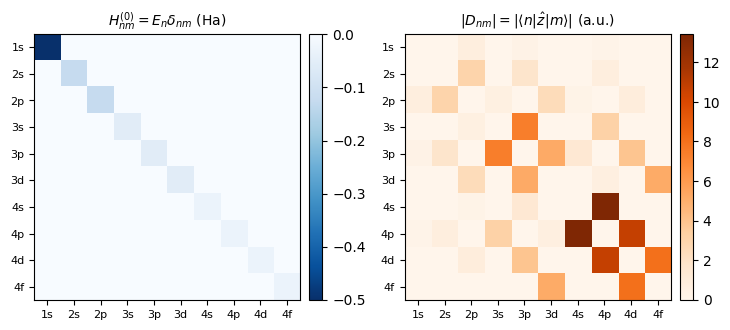

In [4]:
def angular(l1, l2):
    # integral of Y_{l1,0}^* cos(theta) Y_{l2,0}, equation (11)
    if l1 == l2 + 1:
        return l1 / np.sqrt((2 * l1 - 1) * (2 * l1 + 1))
    if l2 == l1 + 1:
        return l2 / np.sqrt((2 * l2 - 1) * (2 * l2 + 1))
    return 0.0

radial_r = (R_all * weights * r_grid**3) @ R_all.T              # radial integrals of r
D = np.array([[radial_r[i, j] * angular(NL[i][1], NL[j][1]) for j in range(DIM)] for i in range(DIM)])

assert np.allclose(D, D.T, atol=1e-12)                                      # real symmetric matrix
assert np.allclose(np.diag(D), 0.0, atol=1e-12)                             # parity, D_nn = 0
for i, (ni, li) in enumerate(NL):
    for j, (nj, lj) in enumerate(NL):
        if abs(li - lj) != 1:
            assert abs(D[i, j]) < 1e-12                                     # selection rule l' = l +- 1
D_eg = D[E_IDX, G_IDX]
assert abs(D_eg - 128 * np.sqrt(2) / 243) < 1e-10                          # equation (12)
print("orbitals coupled to 1s:", [LABELS[j] for j in range(DIM) if abs(D[G_IDX, j]) > 1e-12])
print(f"D(2p,1s) = {D_eg:.6f},  128 sqrt2 / 243 = {128*np.sqrt(2)/243:.6f}")
NUMBERS["DipoleTwopOnes"] = f"{D_eg:.3f}"

fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.3))
im0 = axes[0].imshow(H0, cmap="Blues_r")
axes[0].set_title(r"$H^{(0)}_{nm}=E_n\delta_{nm}$ (Ha)")
im1 = axes[1].imshow(np.abs(D), cmap="Oranges")
axes[1].set_title(r"$|D_{nm}|=|\langle n|\hat z|m\rangle|$ (a.u.)")
for ax, im in zip(axes, (im0, im1)):
    ax.set_xticks(range(DIM)); ax.set_xticklabels(LABELS, fontsize=8)
    ax.set_yticks(range(DIM)); ax.set_yticklabels(LABELS, fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.tight_layout(); save(fig, "fig_lab067_orbital_matrices"); plt.show()

The left panel is the Hamiltonian without light, diagonal with the energies of equation (4). The right panel is the dipole matrix. Its nonzero entries form a chessboard pattern, because only orbitals whose $l$ differs by one are coupled, and they grow with $n$, since the outer orbitals are larger. The 1s row couples only to the p orbitals.

The code shows the light term of equation (13) at three moments of one optical period. We choose the field amplitude through the Rabi frequency $\Omega=E_0D_{2p,1s}$ of the future qubit, here $\Omega=0.02$ in atomic units, and tune the laser to the 1s–2p transition.

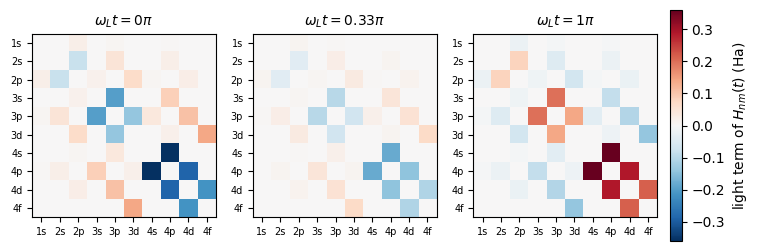

In [5]:
Omega_demo = 0.02
E0_demo = Omega_demo / D_eg
phases = [0.0, np.pi / 3, np.pi]
vmax = E0_demo * np.abs(D).max()
fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.0))
for ax, ph in zip(axes, phases):
    light = E0_demo * np.cos(ph) * D                           # off-diagonal part of H(t), equation (13)
    im = ax.imshow(light, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(rf"$\omega_Lt={ph/np.pi:.2g}\pi$")
    ax.set_xticks(range(DIM)); ax.set_xticklabels(LABELS, fontsize=7)
    ax.set_yticks(range(DIM)); ax.set_yticklabels(LABELS, fontsize=7)
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="light term of $H_{nm}(t)$ (Ha)")
save(fig, "fig_lab067_light_snapshots"); plt.show()
H_t = H0 + E0_demo * np.cos(np.pi / 3) * D
assert np.allclose(np.diag(H_t), E_levels) and np.allclose(H_t, H_t.T)

The diagonal of the Hamiltonian matrix stays fixed. Every coupling allowed by the selection rules swings between positive and negative values at the laser frequency and passes through zero a quarter period after its maximum. All allowed entries oscillate together, so at this stage the light seems to couple many orbitals at once.

## 4. The interaction picture and the slow couplings

Without light every amplitude rotates at its own frequency $E_n$. We remove this fast rotation by writing the state $|\psi(t)\rangle=\sum_nc_n(t)|n\rangle$ with
$$c_n(t)=a_n(t)\,e^{-iE_nt}. \tag{14}$$
Inserting this into the Schrödinger equation $i\dot c_n=\sum_mH_{nm}(t)\,c_m$ cancels the diagonal terms and leaves
$$i\,\dot a_n=\sum_mV_{nm}(t)\,a_m,\qquad V_{nm}(t)=E_0\cos(\omega_Lt-\phi_L)\,D_{nm}\,e^{i\omega_{nm}t},\qquad \omega_{nm}=E_n-E_m. \tag{15}$$
The amplitudes $a_n$ change only through the light, and the coupling matrix $V(t)$ is the light term multiplied by the phases $e^{i\omega_{nm}t}$. For the pair 1s, 2p on resonance, $\omega_L=\omega_{2p,1s}$, the product of the cosine and the phase contains a constant part. For every other pair the frequencies do not match, and the entry oscillates fast. We plot four entries and then average the whole matrix $V(t)$ over two hundred optical periods.

averaged 2p-1s entry: 0.010000   Omega/2 = 0.010000
largest other averaged entry: 4.3e-06


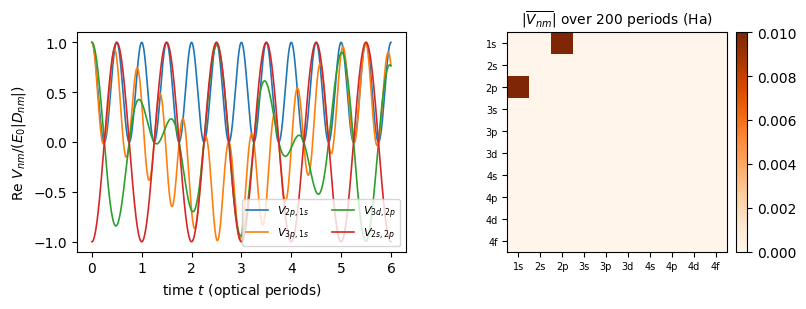

In [6]:
wL = w0                                                        # resonant with 1s-2p
omega_nm = E_levels[:, None] - E_levels[None, :]
def V_matrix(t, E0=E0_demo, wL=wL, phi=0.0):
    return E0 * np.cos(wL * t - phi) * D * np.exp(1j * omega_nm * t)

T_opt = 2 * np.pi / wL
t_trace = np.linspace(0, 6 * T_opt, 1200)
pairs = [("2p", "1s"), ("3p", "1s"), ("3d", "2p"), ("2s", "2p")]
fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.2))
for a, b in pairs:
    i, j = LABELS.index(a), LABELS.index(b)
    trace = np.array([V_matrix(t)[i, j].real for t in t_trace]) / (E0_demo * abs(D[i, j]))
    axes[0].plot(t_trace / T_opt, trace, lw=1.2, label=rf"$V_{{{a},{b}}}$")
axes[0].set_xlabel(r"time $t$ (optical periods)"); axes[0].set_ylabel(r"Re $V_{nm}/(E_0|D_{nm}|)$")
axes[0].legend(fontsize=8, ncol=2, loc="lower right")

t_avg = np.linspace(0, 200 * T_opt, 200 * 64, endpoint=False)
V_avg = np.mean([V_matrix(t) for t in t_avg], axis=0)
im = axes[1].imshow(np.abs(V_avg), cmap="Oranges")
axes[1].set_xticks(range(DIM)); axes[1].set_xticklabels(LABELS, fontsize=7)
axes[1].set_yticks(range(DIM)); axes[1].set_yticklabels(LABELS, fontsize=7)
axes[1].set_title(r"$|\overline{V_{nm}}|$ over 200 periods (Ha)")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.03)
fig.tight_layout(); save(fig, "fig_lab067_interaction_picture"); plt.show()

others = np.abs(V_avg).copy(); others[E_IDX, G_IDX] = others[G_IDX, E_IDX] = 0
print(f"averaged 2p-1s entry: {V_avg[E_IDX, G_IDX].real:.6f}   Omega/2 = {Omega_demo/2:.6f}")
print(f"largest other averaged entry: {others.max():.1e}")
assert abs(V_avg[E_IDX, G_IDX] - Omega_demo / 2) < 1e-6 and others.max() < 1e-3 * Omega_demo

The left panel shows that the 2p–1s entry oscillates around a positive mean, while the entries 3p–1s, 3d–2p and 2s–2p oscillate around zero. The right panel shows the average of the whole matrix. Only the pair 1s, 2p survives, with the value $\Omega/2=E_0D_{2p,1s}/2$, and every other entry averages to less than a thousandth of it. The slow coupling of this one pair is the origin of the two-level system.

## 5. The rotating-wave approximation

We keep only the ground state $|g\rangle=|1s\rangle$ and the excited state $|e\rangle=|2p\rangle$, with the transition frequency $\omega_0=E_e-E_g$ and the detuning $\Delta=\omega_L-\omega_0$ of the laser. Equation (15) for these two amplitudes reads
$$i\,\dot a_g=E_0D_{eg}\cos(\omega_Lt-\phi_L)\,e^{-i\omega_0t}\,a_e,\qquad i\,\dot a_e=E_0D_{eg}\cos(\omega_Lt-\phi_L)\,e^{i\omega_0t}\,a_g. \tag{16}$$
Writing the cosine as $\frac12\big(e^{i(\omega_Lt-\phi_L)}+e^{-i(\omega_Lt-\phi_L)}\big)$ splits the coupling of $a_e$ into two terms,
$$e^{i\omega_0t}\cos(\omega_Lt-\phi_L)=\tfrac12\,e^{i\phi_L}e^{-i\Delta t}+\tfrac12\,e^{-i\phi_L}e^{i(\omega_0+\omega_L)t}. \tag{17}$$
The first term varies slowly, at the detuning $\Delta$. The second oscillates at $\omega_0+\omega_L\approx2\omega_0$. During one Rabi period $2\pi/\Omega$ the slow term turns the amplitudes completely, while the fast term changes them by an amount of order $\Omega/(2\omega_0)$ and then reverses the change. For $\Omega,|\Delta|\ll\omega_0$ we drop the fast term, which is the rotating-wave approximation. With the Rabi frequency $\Omega=E_0D_{eg}$ this leaves
$$i\,\dot a_g=\frac\Omega2\,e^{-i\phi_L}e^{i\Delta t}\,a_e,\qquad i\,\dot a_e=\frac\Omega2\,e^{i\phi_L}e^{-i\Delta t}\,a_g. \tag{18}$$
The remaining time dependence $e^{\pm i\Delta t}$ disappears in the amplitudes $b_g=a_ge^{-i\Delta t/2}$ and $b_e=a_ee^{i\Delta t/2}$. Differentiating and inserting equation (18) gives $i\dot b=\hat{\mathcal H}_{\rm RF}b$ with the constant Hamiltonian
$$\hat{\mathcal H}_{\rm RF}=\begin{pmatrix}\Delta/2&(\Omega/2)\,e^{-i\phi_L}\\(\Omega/2)\,e^{i\phi_L}&-\Delta/2\end{pmatrix}=\frac\Delta2\hat Z+\frac\Omega2\big(\cos\phi_L\,\hat X+\sin\phi_L\,\hat Y\big). \tag{19}$$
The amplitudes $b$ differ from the original $c$ only by phases. With the mean energy $\bar E=(E_g+E_e)/2$ they are
$$\begin{pmatrix}b_g\\b_e\end{pmatrix}=e^{i\bar Et}\,e^{-i\omega_Lt\hat Z/2}\begin{pmatrix}c_g\\c_e\end{pmatrix}, \tag{20}$$
a reference frame that rotates with the laser, and level probabilities are equal in both frames. The same two-level atom without the approximation has the Hamiltonian $-\frac{\omega_0}2\hat Z+\Omega\cos(\omega_Lt-\phi_L)\hat X$, with the zero of energy at $\bar E$.

We compare the two-level evolution with and without the approximation for $\Omega/\omega_0=0.01$, $0.1$ and $0.3$. Before looking at the result, estimate the largest population difference in each case from the ratio $\Omega/(2\omega_0)$.

In [7]:
def evolve(Hfun, T, y0, t_eval=None):
    # integrate i dy/dt = H(t) y with an adaptive Runge-Kutta method of order 8
    f = lambda t, y: -1j * (Hfun(t) @ y)
    return solve_ivp(f, (0.0, T), y0, t_eval=t_eval, rtol=1e-10, atol=1e-12, method="DOP853")

def H_two_level_lab(Omega, wL, phi=0.0):
    return lambda t: -0.5 * w0 * Z + Omega * np.cos(wL * t - phi) * X

g0 = np.array([1, 0], dtype=complex)
rwa_err = {}
curves = {}
for ratio in (0.01, 0.1, 0.3):
    Om = ratio * w0
    T = 2 * np.pi / Om
    t_eval = np.linspace(0, T, 1500)
    sol = evolve(H_two_level_lab(Om, w0), T, g0, t_eval)
    P_full = np.abs(sol.y[1])**2
    P_rwa = np.sin(Om * t_eval / 2)**2                          # resonant solution of equation (19)
    rwa_err[ratio] = np.abs(P_full - P_rwa).max()
    curves[ratio] = (t_eval * Om / (2 * np.pi), P_full, P_rwa)
    print(f"Omega/omega0 = {ratio:4.2f}: largest population difference {rwa_err[ratio]:.4f}")
assert rwa_err[0.01] < 5e-3 and rwa_err[0.01] < rwa_err[0.1] < rwa_err[0.3]
NUMBERS["RwaErrSmall"] = f"{rwa_err[0.01]:.4f}"
NUMBERS["RwaErrMid"] = f"{rwa_err[0.1]:.3f}"
NUMBERS["RwaErrLarge"] = f"{rwa_err[0.3]:.3f}"

Omega/omega0 = 0.01: largest population difference 0.0025
Omega/omega0 = 0.10: largest population difference 0.0258
Omega/omega0 = 0.30: largest population difference 0.0788


The difference grows with the drive strength roughly in proportion to $\Omega/\omega_0$. The fast term of equation (17) also shifts the resonance itself. To measure this shift we use the evolution operator over one optical period $T_L=2\pi/\omega_L$. For a Hamiltonian that repeats with this period, the one-period operator has two eigenvalues with phases. Their difference, divided by $T_L$, is the generalised Rabi frequency $\sqrt{\Omega^2+(\Delta-\delta)^2}$, where $\delta$ is the shift of the resonance. Minimising this frequency over $\omega_L$ locates the resonance. The rotating-wave approximation predicts $\delta=0$, and the dropped term gives the Bloch–Siegert shift
$$\delta_{\rm BS}=\frac{\Omega^2}{4\omega_0}. \tag{21}$$

Omega/omega0 = 0.02: shift 3.749e-05, Omega^2/(4 omega0) = 3.750e-05, ratio 1.000
Omega/omega0 = 0.05: shift 2.341e-04, Omega^2/(4 omega0) = 2.344e-04, ratio 0.999
Omega/omega0 = 0.10: shift 9.334e-04, Omega^2/(4 omega0) = 9.375e-04, ratio 0.996
Omega/omega0 = 0.20: shift 3.685e-03, Omega^2/(4 omega0) = 3.750e-03, ratio 0.983
Omega/omega0 = 0.30: shift 8.115e-03, Omega^2/(4 omega0) = 8.437e-03, ratio 0.962


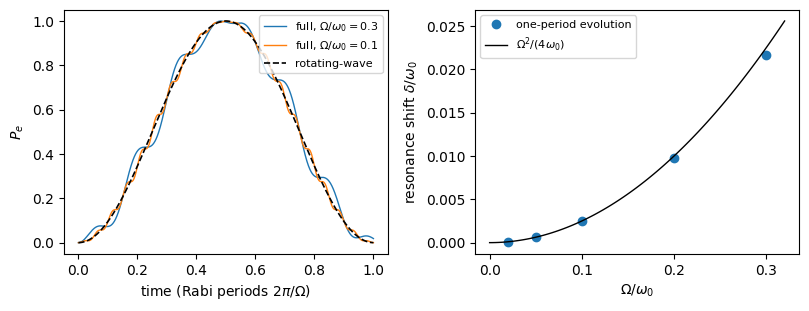

In [8]:
def one_period_operator(Hfun, wL, dim):
    T = 2 * np.pi / wL
    f = lambda t, y: (-1j * Hfun(t) @ y.reshape(dim, dim)).ravel()
    sol = solve_ivp(f, (0.0, T), np.eye(dim, dtype=complex).ravel(), rtol=1e-11, atol=1e-13, method="DOP853")
    return sol.y[:, -1].reshape(dim, dim), T

def rabi_frequency(Hfun_of_wL, wL, dim, qubit_idx):
    # generalised Rabi frequency from the two Floquet phases with most weight on the qubit levels
    U, T = one_period_operator(Hfun_of_wL(wL), wL, dim)
    lam, vec = np.linalg.eig(U)
    weight = (np.abs(vec[qubit_idx, :])**2).sum(axis=0)
    k = np.argsort(weight)[-2:]
    return abs(np.angle(lam[k[0]] / lam[k[1]])) / T

def resonance_shift(Hfun_of_wL, dim, qubit_idx, Om):
    res = minimize_scalar(lambda d: rabi_frequency(Hfun_of_wL, w0 + d, dim, qubit_idx),
                          bounds=(-0.3 * Om, 0.6 * Om), method="bounded", options={"xatol": 1e-9})
    return res.x

bs_ratios = np.array([0.02, 0.05, 0.1, 0.2, 0.3])
bs_shift = np.array([resonance_shift(lambda wl, Om=r*w0: H_two_level_lab(Om, wl), 2, [0, 1], r * w0)
                     for r in bs_ratios])
bs_pred = (bs_ratios * w0)**2 / (4 * w0)
for r, s, p in zip(bs_ratios, bs_shift, bs_pred):
    print(f"Omega/omega0 = {r:4.2f}: shift {s:.3e}, Omega^2/(4 omega0) = {p:.3e}, ratio {s/p:.3f}")
assert abs(bs_shift[0] / bs_pred[0] - 1) < 0.01
NUMBERS["BSRatioSmall"] = f"{bs_shift[0]/bs_pred[0]:.3f}"

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.2))
for ratio, ls in ((0.3, "-"), (0.1, "-")):
    x, Pf, Pr = curves[ratio]
    axes[0].plot(x, Pf, ls, lw=1.0, label=rf"full, $\Omega/\omega_0={ratio}$")
axes[0].plot(curves[0.1][0], curves[0.1][2], "k--", lw=1.2, label="rotating-wave")
axes[0].set_xlabel(r"time (Rabi periods $2\pi/\Omega$)"); axes[0].set_ylabel(r"$P_e$")
axes[0].legend(fontsize=8, loc="upper right")
axes[1].plot(bs_ratios, bs_shift / w0, "o", label="one-period evolution")
xs = np.linspace(0, 0.32, 100)
axes[1].plot(xs, xs**2 / 4, "k-", lw=1, label=r"$\Omega^2/(4\omega_0)$")
axes[1].set_xlabel(r"$\Omega/\omega_0$"); axes[1].set_ylabel(r"resonance shift $\delta/\omega_0$")
axes[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "fig_lab067_rwa"); plt.show()

The left panel shows the excited-state population. At $\Omega/\omega_0=0.1$ the full evolution follows the rotating-wave curve with a small ripple at twice the optical frequency, and at $0.3$ the ripple reaches several per cent. The right panel shows that the resonance moves up by $\Omega^2/(4\omega_0)$ for weak drives and less for strong ones, where higher orders matter. The rotating-wave approximation fails for strong drives, $\Omega$ comparable with $\omega_0$, which occur in the ultrastrong coupling of superconducting circuits. Optical transitions of atoms are driven with $\Omega/\omega_0$ far below $10^{-3}$, where the error of the approximation is negligible.

## 6. The two-level system and its Pauli language

The projector on the two levels,
$$\hat P=|g\rangle\langle g|+|e\rangle\langle e|, \tag{22}$$
cuts the atom down to the qubit, and the Hamiltonian of the qubit is the $2\times2$ block $\hat P\hat{\mathcal H}\hat P$. Four operators span all operators on this two-dimensional space, the projectors on the two levels and the two transition operators. With $|g\rangle=|0\rangle=|\uparrow\rangle$ they are
$$|g\rangle\langle g|=\tfrac12(\hat I+\hat Z),\quad |e\rangle\langle e|=\tfrac12(\hat I-\hat Z),\quad |g\rangle\langle e|=\hat S^+=\tfrac12\hat\sigma^+,\quad |e\rangle\langle g|=\hat S^-=\tfrac12\hat\sigma^-, \tag{23}$$
with $\hat\sigma^\pm=\hat X\pm i\hat Y$. Inverting these relations,
$$\hat X=|g\rangle\langle e|+|e\rangle\langle g|,\qquad \hat Y=-i|g\rangle\langle e|+i|e\rangle\langle g|,\qquad \hat Z=|g\rangle\langle g|-|e\rangle\langle e|. \tag{24}$$
In this convention spin up is the ground state, so $\hat\sigma^+$ raises the spin and lowers the energy, and the decay of the excited state is $\hat S^+=|g\rangle\langle e|$.

Every Hermitian $2\times2$ matrix has the Pauli expansion
$$\mathcal H=c_0\hat I+c_x\hat X+c_y\hat Y+c_z\hat Z,\qquad c_a=\tfrac12\,{\rm Tr}(\hat\sigma_a\mathcal H). \tag{25}$$
We build the block of the atom in the rotating frame of equation (20) numerically. The Hamiltonian matrix of equation (13) is projected on the two levels and transformed to the rotating frame. Its average over one optical period gives the coefficients of equation (25). We use a detuning $\Delta=0.3\,\Omega$ and the laser phases $\phi_L=0$ and $\phi_L=\pi/3$.

In [9]:
gg = np.array([[1, 0], [0, 0]], dtype=complex); ee = np.array([[0, 0], [0, 1]], dtype=complex)
ge = np.array([[0, 1], [0, 0]], dtype=complex); eg = ge.T.copy()           # |g><e| and |e><g|
sigma_p, sigma_m = X + 1j * Y, X - 1j * Y
assert np.allclose(gg, (I2 + Z) / 2) and np.allclose(ee, (I2 - Z) / 2)
assert np.allclose(ge, sigma_p / 2) and np.allclose(eg, sigma_m / 2)       # equation (23)
assert np.allclose(X, ge + eg) and np.allclose(Y, -1j * ge + 1j * eg) and np.allclose(Z, gg - ee)

def pauli_coefficients(M):
    return {a: 0.5 * np.trace(s @ M).real for a, s in (("0", I2), ("x", X), ("y", Y), ("z", Z))}

def rotating_frame_block(E0, wL, phi, n_samples=4000):
    # P H(t) P in the rotating frame of equation (20), averaged over one optical period
    idx = [G_IDX, E_IDX]
    Ebar = E_levels[idx].mean()
    ts = np.linspace(0, 2 * np.pi / wL, n_samples, endpoint=False)
    acc = np.zeros((2, 2), dtype=complex)
    for t in ts:
        Hlab = (H0 + E0 * np.cos(wL * t - phi) * D)[np.ix_(idx, idx)] - Ebar * I2
        Rt = np.diag([np.exp(-1j * wL * t / 2), np.exp(1j * wL * t / 2)])   # e^{-i wL t Z/2}
        acc += Rt @ Hlab @ Rt.conj().T + 0.5 * wL * Z                       # R H R^dagger + i (dR/dt) R^dagger
    return acc / n_samples

Delta_demo = 0.3 * Omega_demo
for phi in (0.0, np.pi / 3):
    block = rotating_frame_block(E0_demo, w0 + Delta_demo, phi)
    c = pauli_coefficients(block)
    print(f"phi_L = {phi:.3f}: block =\n{np.round(block, 6)}")
    print("   coefficients:", {k: round(v, 6) for k, v in c.items()})
    assert abs(c["0"]) < 1e-12 and abs(c["z"] - Delta_demo / 2) < 1e-9
    assert abs(c["x"] - Omega_demo / 2 * np.cos(phi)) < 1e-9 and abs(c["y"] - Omega_demo / 2 * np.sin(phi)) < 1e-9

phi_L = 0.000: block =
[[ 0.003-0.j  0.01 -0.j]
 [ 0.01 +0.j -0.003-0.j]]
   coefficients: {'0': np.float64(0.0), 'x': np.float64(0.01), 'y': np.float64(0.0), 'z': np.float64(0.003)}
phi_L = 1.047: block =
[[ 0.003-0.j       0.005-0.00866j]
 [ 0.005+0.00866j -0.003-0.j     ]]
   coefficients: {'0': np.float64(0.0), 'x': np.float64(0.005), 'y': np.float64(0.00866), 'z': np.float64(0.003)}


The averaged block equals equation (19). The coefficient of $\hat Z$ is half the detuning, and the coefficient of $\hat X$ is half the Rabi frequency. The laser phase $\phi_L=\pi/3$ moves part of the weight from $\hat X$ to $\hat Y$ in the ratio $\cos\phi_L:\sin\phi_L$. The coefficient $c_0$ vanishes because we measured energies from the mean level $\bar E$. A nonzero $c_0$ would multiply the state by the global phase $e^{-ic_0t}$, which no measurement detects.

The Pauli expansion translates the physics of the atom into operations on a qubit.

| atom | qubit |
|---|---|
| ground state 1s, excited state 2p | $\lvert 0\rangle$, $\lvert 1\rangle$ |
| detuning $\Delta$, free precession for a time $t$ | rotation $\hat R_z(\Delta t)$ about $z$ |
| resonant pulse of area $\theta=\Omega t$ and phase $\phi_L$ | rotation $\hat R_{\phi_L}(\theta)=e^{-i\theta(\cos\phi_L\hat X+\sin\phi_L\hat Y)/2}$ |
| fluorescence detection of the level | measurement of $\hat Z$ |
| spontaneous decay $e\to g$ | jump operator $\hat S^+=\lvert g\rangle\langle e\rvert$ |

A jump operator describes a sudden transition between two levels, here the emission of a photon that takes the atom from $e$ to $g$.

## 7. The full driven atom

We test these approximations on the full atom by integrating the Schrödinger equation with the Hamiltonian matrix of equation (13) for all ten orbitals, without any approximation in time. The atom starts in 1s, and the resonant laser has the Rabi frequency $\Omega=0.005$. One Rabi period then lasts about 75 optical periods. The corresponding field, $E_0\approx3.5\times10^9$ V/m, is much stronger than in a laboratory, where Rabi periods span millions of optical periods. The ratio $\Omega/\omega_0\approx0.013$ keeps the physics of a weak drive while the simulation stays short. The two-level prediction on resonance is $P_{2p}(t)=\sin^2(\Omega t/2)$, and for a detuning $\Delta$ the largest population reached is
$$P_{2p}^{\max}=\frac{\Omega^2}{\Omega^2+\Delta^2},\qquad\text{at the time }t=\frac\pi{\sqrt{\Omega^2+\Delta^2}}. \tag{26}$$

field E0 = 0.0067 a.u. = 3.45e+09 V/m, optical periods per Rabi period: 75
largest deviation from sin^2(Omega t/2): 0.0066, largest population outside 1s, 2p: 0.0050
largest deviation from equation (26): 0.0187


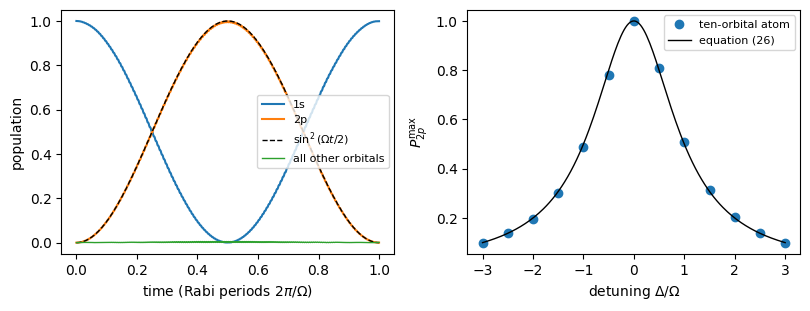

In [10]:
def H_atom(E0, wL, phi=0.0):
    return lambda t: H0 + E0 * np.cos(wL * t - phi) * D

def ground_state():
    y = np.zeros(DIM, dtype=complex); y[G_IDX] = 1.0
    return y

Omega_w = 0.005
E0_w = Omega_w / D_eg
T_rabi = 2 * np.pi / Omega_w
t_eval = np.linspace(0, T_rabi, 600)
sol = evolve(H_atom(E0_w, w0), T_rabi, ground_state(), t_eval)
P = np.abs(sol.y)**2
P_rabi = np.sin(Omega_w * t_eval / 2)**2
rabi_err = np.abs(P[E_IDX] - P_rabi).max()
other_max = (1 - P[G_IDX] - P[E_IDX]).max()
print(f"field E0 = {E0_w:.4f} a.u. = {E0_w * F_AU:.2e} V/m, optical periods per Rabi period: {T_rabi / (2*np.pi/w0):.0f}")
print(f"largest deviation from sin^2(Omega t/2): {rabi_err:.4f}, largest population outside 1s, 2p: {other_max:.4f}")
assert rabi_err < 1e-2 and other_max < 1e-2
NUMBERS["FieldVm"] = f"{E0_w * F_AU / 1e9:.1f}"
NUMBERS["RabiErr"] = f"{rabi_err:.4f}"
NUMBERS["OtherMax"] = f"{other_max:.4f}"

detunings = np.linspace(-3, 3, 13) * Omega_w
Pmax_sim, Pmax_th = [], []
for Dl in detunings:
    Oeff = np.hypot(Omega_w, Dl); Tp = np.pi / Oeff
    s = evolve(H_atom(E0_w, w0 + Dl), Tp, ground_state(), [Tp])
    Pmax_sim.append(abs(s.y[E_IDX, -1])**2); Pmax_th.append(Omega_w**2 / Oeff**2)
Pmax_sim, Pmax_th = np.array(Pmax_sim), np.array(Pmax_th)
detune_err = np.abs(Pmax_sim - Pmax_th).max()
print(f"largest deviation from equation (26): {detune_err:.4f}")
assert detune_err < 2e-2
NUMBERS["DetuneErr"] = f"{detune_err:.3f}"

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.2))
x = t_eval / T_rabi
axes[0].plot(x, P[G_IDX], lw=1.5, label="1s")
axes[0].plot(x, P[E_IDX], lw=1.5, label="2p")
axes[0].plot(x, P_rabi, "k--", lw=1, label=r"$\sin^2(\Omega t/2)$")
axes[0].plot(x, 1 - P[G_IDX] - P[E_IDX], lw=1, label="all other orbitals")
axes[0].set_xlabel(r"time (Rabi periods $2\pi/\Omega$)"); axes[0].set_ylabel("population")
axes[0].legend(fontsize=8, loc="center right")
axes[1].plot(detunings / Omega_w, Pmax_sim, "o", label="ten-orbital atom")
dd = np.linspace(-3, 3, 200)
axes[1].plot(dd, 1 / (1 + dd**2), "k-", lw=1, label="equation (26)")
axes[1].set_xlabel(r"detuning $\Delta/\Omega$"); axes[1].set_ylabel(r"$P_{2p}^{\max}$")
axes[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "fig_lab067_rabi"); plt.show()

The populations of 1s and 2p exchange with the Rabi period and follow the two-level curve to better than one per cent. All other orbitals together never hold more than about half a per cent. The detuning scan follows the Lorentzian of equation (26). The atom with ten orbitals behaves as a two-level system with the Rabi frequency computed from the single matrix element of equation (12).

## 8. Limits of the two-level description

The other orbitals are nearly empty, and they still shift the qubit levels. A level $r$ coupled to a level $n$ with the Rabi frequency $\Omega_{nr}=E_0D_{nr}$ shifts its energy, to second order in the field, by
$$\delta E_n=\sum_{r}\frac{\Omega_{nr}^2}{4}\left(\frac1{\omega_{nr}-\omega_L}+\frac1{\omega_{nr}+\omega_L}\right), \tag{27}$$
where the resonant term of the qubit pair itself is left out because the rotating-wave approximation keeps it in full. The counter-rotating term of the pair is kept, and it reproduces the Bloch–Siegert shift of equation (21). The shift of the qubit resonance is $\delta=\delta E_e-\delta E_g$, the light shift. It grows with the square of the field, and so does the population that leaks into the other orbitals during a pulse.

Before looking at the result, decide how the leakage changes when the Rabi frequency doubles.

Omega = 0.01: resonance shift 4.857e-04, equation (27) 4.894e-04, ratio 0.993
Omega = 0.02: resonance shift 1.902e-03, equation (27) 1.957e-03, ratio 0.972
Omega = 0.04: resonance shift 7.066e-03, equation (27) 7.830e-03, ratio 0.902
largest leakage during a pi pulse: {np.float64(0.005): np.float64(0.0057), np.float64(0.01): np.float64(0.02237), np.float64(0.02): np.float64(0.08845), np.float64(0.04): np.float64(0.30507), np.float64(0.08): np.float64(0.6138)}  log-log slope 1.98


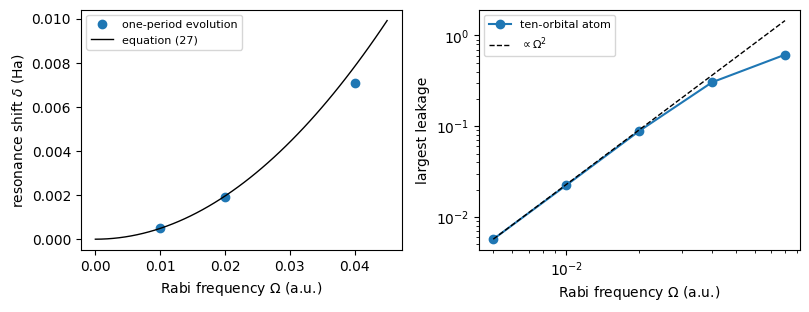

In [11]:
def predicted_shift(E0, wL):
    dE = np.zeros(DIM)
    for n in range(DIM):
        for m in range(DIM):
            if n == m or abs(D[n, m]) < 1e-12:
                continue
            Om_nm = E0 * D[n, m]
            for sign in (+1, -1):
                den = omega_nm[n, m] + sign * wL
                if {n, m} == {G_IDX, E_IDX} and abs(den) < 0.5 * wL:
                    continue                                    # resonant term of the qubit pair
                if abs(den) > 1e-12:
                    dE[n] += Om_nm**2 / 4 / den
    return dE[E_IDX] - dE[G_IDX]

shift_Omegas = np.array([0.01, 0.02, 0.04])
shift_num = np.array([resonance_shift(lambda wl, E0=Om/D_eg: H_atom(E0, wl), DIM, [G_IDX, E_IDX], Om)
                      for Om in shift_Omegas])
shift_pred = np.array([predicted_shift(Om / D_eg, w0) for Om in shift_Omegas])
for Om, s, p in zip(shift_Omegas, shift_num, shift_pred):
    print(f"Omega = {Om:.2f}: resonance shift {s:.3e}, equation (27) {p:.3e}, ratio {s/p:.3f}")
assert abs(shift_num[0] / shift_pred[0] - 1) < 0.02
NUMBERS["ShiftNum"] = f"{shift_num[1]:.2e}"
NUMBERS["ShiftPred"] = f"{shift_pred[1]:.2e}"

leak_Omegas = np.array([0.005, 0.01, 0.02, 0.04, 0.08])
leakage = []
for Om in leak_Omegas:
    Tp = np.pi / Om
    s = evolve(H_atom(Om / D_eg, w0), Tp, ground_state(), np.linspace(0, Tp, 400))
    Pq = np.abs(s.y[G_IDX])**2 + np.abs(s.y[E_IDX])**2
    leakage.append((1 - Pq).max())
leakage = np.array(leakage)
slope = np.polyfit(np.log(leak_Omegas[:3]), np.log(leakage[:3]), 1)[0]          # weak-field slope
print("largest leakage during a pi pulse:", dict(zip(leak_Omegas, np.round(leakage, 5))), f" log-log slope {slope:.2f}")
assert 1.6 < slope < 2.4
NUMBERS["LeakSlope"] = f"{slope:.1f}"
NUMBERS["LeakStrong"] = f"{leakage[-1]:.3f}"

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.2))
axes[0].plot(shift_Omegas, shift_num, "o", label="one-period evolution")
oo = np.linspace(0, 0.045, 50)
axes[0].plot(oo, [predicted_shift(o / D_eg, w0) for o in oo], "k-", lw=1, label="equation (27)")
axes[0].set_xlabel(r"Rabi frequency $\Omega$ (a.u.)"); axes[0].set_ylabel(r"resonance shift $\delta$ (Ha)")
axes[0].legend(fontsize=8)
axes[1].loglog(leak_Omegas, leakage, "o-", label="ten-orbital atom")
axes[1].loglog(leak_Omegas, leakage[0] * (leak_Omegas / leak_Omegas[0])**2, "k--", lw=1, label=r"$\propto\Omega^2$")
axes[1].set_xlabel(r"Rabi frequency $\Omega$ (a.u.)"); axes[1].set_ylabel("largest leakage")
axes[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "fig_lab067_limits"); plt.show()

The left panel shows that the resonance of the ten-orbital atom moves with the square of the field, as equation (27) predicts. The prediction agrees within one per cent at the weakest field. The light shift is several times larger than the Bloch–Siegert shift of the isolated pair, because the 2p level couples strongly to 3d and 3s. The right panel shows that the leakage out of the qubit grows as $\Omega^2$ at weak fields, so doubling the Rabi frequency quadruples it. The leakage reaches tens of per cent when $\Omega/\omega_0$ approaches 0.1. A laser tuned to the bare transition frequency is therefore slightly detuned from the shifted resonance, and a fast gate leaks more. Both effects set a speed limit for gates on a given atom. The basis of ten orbitals omits the higher bound states and the continuum, which add further small shifts of the same kind.

## 9. Spontaneous emission

The excited level also decays by emitting a photon, an effect of the quantised light field that the classical description used here does not contain. Its rate is
$$\Gamma=\frac{\omega_0^3\,|d_{eg}|^2}{3\pi\varepsilon_0\hbar c^3}, \tag{28}$$
with the dipole matrix element $d_{eg}=-e_0a_0D_{2p,1s}$ and the speed of light $c$. We evaluate it in SI units.

In [12]:
w0_SI = w0 / T_AU                                              # rad/s
d_SI = const.e * A0_M * D_eg                                   # C m
Gamma = w0_SI**3 * d_SI**2 / (3 * np.pi * const.epsilon_0 * const.hbar * const.c**3)
lifetime_ns = 1e9 / Gamma
cycles = w0_SI / (2 * np.pi) / Gamma
print(f"Gamma = {Gamma:.3e} 1/s, lifetime 1/Gamma = {lifetime_ns:.3f} ns, optical cycles per lifetime {cycles:.2e}")
assert 1.5 < lifetime_ns < 1.7
NUMBERS["LifetimeNs"] = f"{lifetime_ns:.2f}"
NUMBERS["CyclesPerLifetime"] = f"{cycles/1e6:.1f}"

Gamma = 6.268e+08 1/s, lifetime 1/Gamma = 1.595 ns, optical cycles per lifetime 3.94e+06


The 2p level of hydrogen lives about 1.6 ns, roughly four million optical cycles. Over the short pulses simulated here the decay is negligible, so the closed two-level description holds. For computation, which needs many gates in sequence, a nanosecond is far too short. Atomic and ionic qubits therefore use pairs of long-lived levels, such as two hyperfine levels of the ground state or a metastable excited state. They are driven with microwaves, with pairs of laser beams or on narrow optical transitions. For each such pair the matrix element of the drive between the two levels takes the place of the dipole matrix element $d_{eg}$, and the rotating-wave approximation gives the Hamiltonian of equation (19) with the Rabi frequency set by that matrix element. The decay that remains appears in the qubit language as the jump $\hat S^+=|g\rangle\langle e|$ with the relaxation time $T_1=1/\Gamma$.

## 10. Laser pulses as quantum gates

A resonant pulse of duration $t$ rotates the qubit by the angle $\theta=\Omega t$ about the axis $(\cos\phi_L,\sin\phi_L,0)$ of the Bloch sphere, by equation (19). A $\pi/2$ pulse takes the ground state to the equator, and a $\pi$ pulse exchanges the two levels. We apply such pulses to the ten-orbital atom and transform the 1s and 2p amplitudes to the rotating frame with equation (20). Their Bloch vector is
$$\mathbf r=\big(\langle\hat X\rangle,\langle\hat Y\rangle,\langle\hat Z\rangle\big)=\big(2\,{\rm Re}(b_g^*b_e),\;2\,{\rm Im}(b_g^*b_e),\;|b_g|^2-|b_e|^2\big). \tag{29}$$
For the ideal rotation $\hat R_{\phi_L}(\theta)$ the Bloch vector starting at the north pole moves to $(\sin\theta\sin\phi_L,\,-\sin\theta\cos\phi_L,\,\cos\theta)$. To compare a pulse on the full atom with the ideal gate we use the average gate fidelity of the $2\times2$ block $U$ of the evolution, $F=\big(|{\rm Tr}(U_{\rm ideal}^\dagger U)|^2+{\rm Tr}(U^\dagger U)\big)/6$. It equals one only for the ideal gate and drops when population leaks out of the qubit.

pi/2 pulse, phi_L = 0.000: final Bloch vector [-0.018 -0.996  0.002], ideal [ 0. -1.  0.]
pi/2 pulse, phi_L = 1.571: final Bloch vector [ 0.999 -0.031 -0.   ], ideal [ 1. -0.  0.]
pi pulse with Omega = 0.005: gate error 1 - F = 6.03e-04
pi pulse with Omega = 0.040: gate error 1 - F = 1.74e-01


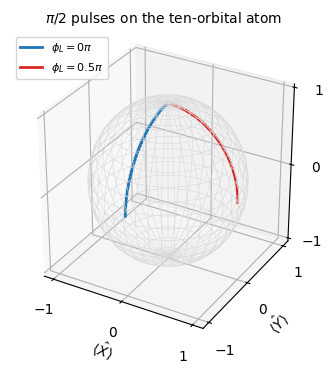

In [13]:
def rotating_amplitudes(c_full, t, wL):
    idx = [G_IDX, E_IDX]
    Ebar = E_levels[idx].mean()
    phase = np.exp(1j * Ebar * t) * np.array([np.exp(-1j * wL * t / 2), np.exp(1j * wL * t / 2)])
    return phase * c_full[idx]

def bloch(b):
    rho01 = np.conj(b[0]) * b[1]
    return np.array([2 * rho01.real, 2 * rho01.imag, np.abs(b[0])**2 - np.abs(b[1])**2])

trajectories = {}
for phi in (0.0, np.pi / 2):
    Tp = (np.pi / 2) / Omega_w
    ts = np.linspace(0, Tp, 200)
    s = evolve(H_atom(E0_w, w0, phi), Tp, ground_state(), ts)
    b = rotating_amplitudes(s.y, ts, w0)
    r = bloch(b)
    ideal_end = np.array([np.sin(np.pi / 2) * np.sin(phi), -np.sin(np.pi / 2) * np.cos(phi), np.cos(np.pi / 2)])
    print(f"pi/2 pulse, phi_L = {phi:.3f}: final Bloch vector {np.round(r[:, -1], 3)}, ideal {np.round(ideal_end, 3)}")
    assert np.linalg.norm(r[:, -1] - ideal_end) < 5e-2
    trajectories[phi] = r

def pulse_block(Om, theta, phi):
    # 2x2 block of the evolution of the ten-orbital atom in the rotating frame
    Tp = theta / Om
    cols = []
    for start in (G_IDX, E_IDX):
        y0 = np.zeros(DIM, dtype=complex); y0[start] = 1.0
        s = evolve(H_atom(Om / D_eg, w0, phi), Tp, y0, [Tp])
        cols.append(rotating_amplitudes(s.y, np.array([Tp]), w0)[:, 0])
    return np.array(cols).T

def gate_fidelity(U, theta, phi):
    U_ideal = expm(-1j * theta / 2 * (np.cos(phi) * X + np.sin(phi) * Y))
    return (abs(np.trace(U_ideal.conj().T @ U))**2 + np.trace(U.conj().T @ U).real) / 6

infid = {}
for Om in (Omega_w, 0.04):
    U = pulse_block(Om, np.pi, 0.0)
    infid[Om] = 1 - gate_fidelity(U, np.pi, 0.0)
    print(f"pi pulse with Omega = {Om:.3f}: gate error 1 - F = {infid[Om]:.2e}")
assert infid[Omega_w] < infid[0.04] and infid[Omega_w] < 1e-2
NUMBERS["GateErrWeak"] = f"{infid[Omega_w]:.1e}"
NUMBERS["GateErrStrong"] = f"{infid[0.04]:.1e}"

fig = plt.figure(figsize=(4.6, 4.0))
ax = fig.add_subplot(projection="3d")
u, v = np.mgrid[0:2*np.pi:40j, 0:np.pi:20j]
ax.plot_wireframe(np.cos(u)*np.sin(v), np.sin(u)*np.sin(v), np.cos(v), color="0.85", lw=0.4)
for phi, col in ((0.0, "C0"), (np.pi / 2, "C3")):
    r = trajectories[phi]
    ax.plot(r[0], r[1], r[2], color=col, lw=2, label=rf"$\phi_L={phi/np.pi:.1g}\pi$")
ax.zaxis.set_rotate_label(False)
ax.set_xlabel(r"$\langle\hat X\rangle$", labelpad=2); ax.set_ylabel(r"$\langle\hat Y\rangle$", labelpad=2)
ax.set_zlabel(r"$\langle\hat Z\rangle$", rotation=0, labelpad=4)
ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1]); ax.set_zticks([-1, 0, 1])
ax.set_box_aspect((1, 1, 1)); ax.legend(fontsize=8, loc="upper left")
ax.set_title(r"$\pi/2$ pulses on the ten-orbital atom")
save(fig, "fig_lab067_pulses"); plt.show()

Both $\pi/2$ pulses start at the north pole, the ground state, and end on the equator. The laser phase turns the axis of rotation, so the pulse with $\phi_L=0$ ends at $-y$ and the pulse with $\phi_L=\pi/2$ ends at $+x$. The ten-orbital atom therefore performs the rotations $\hat R_{\phi_L}(\theta)$ of the qubit. At the weak field the $\pi$ pulse has a gate error below one per cent. At the eight-fold stronger field the error grows, because the light shift detunes the laser from the shifted resonance and population leaks out of the qubit. On the same atom a faster gate is therefore less accurate unless the laser frequency is corrected for the light shift.

### Rotation angles set by pulse area

On resonance the qubit Hamiltonian in the rotating frame is $\frac{\Omega(t)}2(\cos\phi_L\hat X+\sin\phi_L\hat Y)$, where the Rabi frequency $\Omega(t)$ follows the envelope of the laser field. At different times this Hamiltonian differs only by the number $\Omega(t)$, so it commutes with itself, and the product of many short steps collapses to one exponential,
$$\hat U=\hat R_{\phi_L}(\theta)=e^{-i\theta(\cos\phi_L\hat X+\sin\phi_L\hat Y)/2},\qquad \theta=\int_0^T\Omega(t')\,dt' . \tag{30}$$
The rotation angle is the pulse area. A rectangular pulse gives $\theta=\Omega T$, so the angle grows linearly with the duration, and a smooth envelope of the same area gives the same gate. The laser phase only turns the axis. A rotation about $z$ turns $\hat X$ into $\hat R_z(\phi)\hat X\hat R_z(-\phi)=\cos\phi\,\hat X+\sin\phi\,\hat Y$, which gives
$$\hat R_{\phi}(\theta)=\hat R_z(\phi)\,\hat R_x(\theta)\,\hat R_z(-\phi),\qquad \hat R_{\phi}(\theta)\,\hat R_z(\alpha)=\hat R_z(\alpha)\,\hat R_{\phi-\alpha}(\theta). \tag{31}$$
A rotation by $\alpha$ about $z$ before a sequence of pulses therefore equals the same pulses with all phases shifted by $-\alpha$, followed by a final rotation about $z$. That final rotation leaves the probabilities of a readout in the computational basis unchanged. A laboratory applies such rotations by shifting the phases of later pulses, without any pulse at all.

Predict the rotation angle of a $\sin^2$ pulse of peak Rabi frequency $\Omega_0$ and duration $T$ before running the code. The code integrates the two-level Hamiltonian for rectangular pulses of increasing duration and for a $\sin^2$ envelope, and it compares the result with equations (30) and (31).

In [14]:
def time_ordered(H_of_t, T, n=2000):
    # product of short exponentials, latest step leftmost (midpoint rule)
    dt = T / n
    U = np.eye(2, dtype=complex)
    for k in range(n):
        U = expm(-1j * dt * H_of_t((k + 0.5) * dt)) @ U
    return U

def R_phi(theta, phi):
    return expm(-1j * theta / 2 * (np.cos(phi) * X + np.sin(phi) * Y))

Om_c, phi_c = 1.0, 0.4
durations = np.linspace(0.0, 2 * np.pi, 9)
angles = []
for T in durations:
    U = expm(-1j * T * (Om_c / 2) * (np.cos(phi_c) * X + np.sin(phi_c) * Y))
    # angle from the trace, Tr U = 2 cos(theta/2)
    angles.append(2 * np.arccos(np.clip(np.trace(U).real / 2, -1, 1)))
angles = np.array(angles)
assert np.allclose(angles, Om_c * durations, atol=1e-9)          # theta = Omega T, linear in T

T_s, Om0 = 3.0, 1.7
envelope = lambda t: Om0 * np.sin(np.pi * t / T_s) ** 2
area = Om0 * T_s / 2
U_shaped = time_ordered(lambda t: 0.5 * envelope(t) * (np.cos(phi_c) * X + np.sin(phi_c) * Y), T_s)
err_shaped = np.max(np.abs(U_shaped - R_phi(area, phi_c)))
assert err_shaped < 1e-5                                           # equation (30)

Rz_ = lambda a: expm(-1j * a * Z / 2)
alpha = 0.9
assert np.allclose(R_phi(1.3, phi_c), Rz_(phi_c) @ R_phi(1.3, 0.0) @ Rz_(-phi_c))      # equation (31), left
assert np.allclose(R_phi(1.3, phi_c) @ Rz_(alpha), Rz_(alpha) @ R_phi(1.3, phi_c - alpha))  # equation (31), right
psi = R_phi(0.7, 0.0) @ np.array([1, 0], dtype=complex)
with_z = R_phi(0.8, 1.1) @ R_phi(1.9, 0.3) @ Rz_(alpha) @ psi
shifted = R_phi(0.8, 1.1 - alpha) @ R_phi(1.9, 0.3 - alpha) @ psi
assert np.allclose(np.abs(with_z) ** 2, np.abs(shifted) ** 2)
print(f"angle = Omega T on {len(durations)} durations; sin^2 pulse of area {area:.3f} reproduces R_phi(area) to {err_shaped:.1e}")
print("a z rotation equals a phase shift of the later pulses for a computational-basis readout")


angle = Omega T on 9 durations; sin^2 pulse of area 2.550 reproduces R_phi(area) to 1.3e-15
a z rotation equals a phase shift of the later pulses for a computational-basis readout


## 11. Exercises

1. Compute $D_{3p,1s}$ from equation (10) analytically, using $R_{31}$ from equation (5), and compare it with the matrix of Section 3.
2. Change the polarisation of the light to circular, so that it couples $m$ to $m\pm1$. Explain which orbitals with $m\neq0$ must then be added to the basis.
3. Repeat the average of Section 4 with the laser tuned to the 1s–3p transition. Identify the pair that survives and its averaged coupling.
4. Derive equation (19) from equation (18) by differentiating $b_g=a_ge^{-i\Delta t/2}$ and $b_e=a_ee^{i\Delta t/2}$.
5. Use equation (27) to predict the light shift for $\Omega=0.03$, then measure it with the one-period evolution and compare.
6. Find the laser frequency that maximises the $\pi$-pulse fidelity at $\Omega=0.04$ and compare it with the resonance shift of Section 8.

## 12. Summary

An atom becomes a qubit through a chain of controlled approximations. The Born–Oppenheimer approximation reduces the atom to its electrons, whose energy eigenstates form a basis in which the Hamiltonian matrix is diagonal. Classical light polarised along $z$ adds off-diagonal entries only between orbitals whose angular momentum differs by one, and these entries oscillate at the laser frequency. In the interaction picture every coupling oscillates fast except the one between the two levels in resonance with the laser. The rotating-wave approximation keeps this slow coupling, and a frame rotating with the laser turns it into the constant Hamiltonian $\frac\Delta2\hat Z+\frac\Omega2(\cos\phi_L\hat X+\sin\phi_L\hat Y)$. In this Pauli language the detuning generates rotations about $z$, and a resonant pulse rotates the qubit about an axis in the $x$–$y$ plane fixed by the laser phase. Fluorescence measures $\hat Z$, and spontaneous decay is the jump $\hat S^+=|g\rangle\langle e|$. The simulation of hydrogen with ten orbitals confirms the two-level dynamics to better than one per cent at a weak field. It also measures the light shift, the Bloch–Siegert shift and the leakage, which grow with the square of the field. The excited 2p level lives only 1.6 ns, which is why atomic qubits use long-lived pairs of levels described by the same Hamiltonian.